# Tritium Breeding and Neutron Fluence: Spatial and Energy Distributions

<!-- index:description -->
Extend the Fusion Energy Neutronics Workshop's [tritium-breeding task](https://github.com/fusion-energy/neutronics-workshop/blob/main/tasks/task_05_CSG_cell_tally_TBR/1_example_tritium_production.ipynb) beyond tritium breeding ratio (TBR), exploring neutron fluence and tritium production through radial profiles, energy–radius maps, and statistical uncertainties.
<!-- /index:description -->

<!-- generated:structure -->
```text
Tritium Breeding and Neutron Fluence: Spatial and Energy Distributions
├── 0. Cross sections
├── 1. Materials
├── 2. Geometry
├── 3. Mean free paths
├── 4. Settings (with source)
├── 5. Tallies
├── 6. Ready and plot
├── 7. Run
└── 8. Output
    ├── (n,Xt)_convergence
    ├── (n,Xt)
    ├── Neutron fluence: radius–energy maps
    ├── (n,Xt) production: radius–energy maps
    └── Energy-integrated radial contributions per spherical shell
```
<!-- /generated:structure -->

Following a data-science-oriented approach, material compositions and geometric specifications are organized in pandas DataFrames, from which OpenMC objects are constructed programmatically. This minimizes repetitive code, reduces the risk of inconsistencies, and makes the model easier to modify and validate.

The example originated from the [Fusion Energy Neutronics Workshop](https://github.com/fusion-energy/neutronics-workshop/blob/main/tasks/task_05_CSG_cell_tally_TBR/1_example_tritium_production.ipynb), although the original code has since been extensively reworked—perhaps beyond recognition.

In [1]:
import re
from pathlib import Path

import openmc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from openmc_workbench_config import DATA_ROOT

xs_xml = DATA_ROOT / 'endf-b8.1' / 'cross_sections.xml'
openmc.config['cross_sections'] = xs_xml

SOURCE_eV = 14e6
R_VESSEL = 500.
FW_THICK = 10.
BB_THICK = 100.

output_dir = Path('output_0')
output_dir.mkdir(exist_ok=True)

## 0. Cross sections

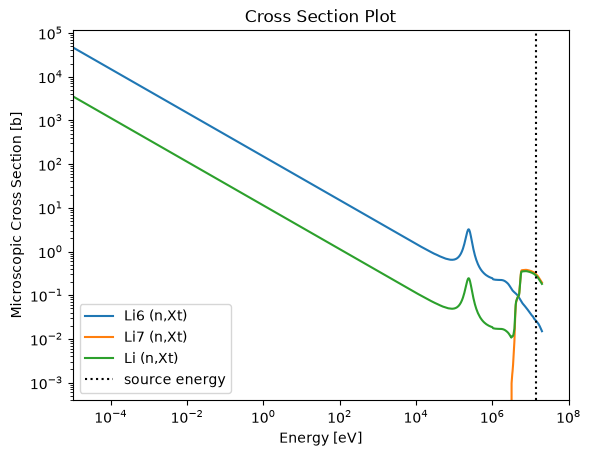

In [2]:
fig = openmc.plotter.plot_xs(
    reactions = {
        'Li6': ['(n,Xt)'],
        'Li7': ['(n,Xt)'],
        'Li': ['(n,Xt)'],
    }
)
ax = fig.axes[0]
ax.axvline(SOURCE_eV, label='source energy',  ls=':', color='k')
ax.set_xlim(right=1e8)
ax.legend()

## 1. Materials

In [3]:
# https://docs.openmc.org/en/stable/pythonapi/generated/openmc.Material.html
mats_df = pd.DataFrame(columns=[
    'name', 'element', 'percent', 'percent_type',
    'enrichment', 'enrichment_target', 'enrichment_type'
])
mats_df.loc[len(mats_df)] = ['breeder', 'Pb', 84.2, 'ao'] + 3 * [None]
mats_df.loc[len(mats_df)] = ['breeder', 'Li', 15.8, 'ao', 50, 'Li6', 'ao']
mats_df.loc[len(mats_df)] = ['steel', 'Fe', 0.95, 'wo'] + 3 * [None]
mats_df.loc[len(mats_df)] = ['steel', 'C', 0.05, 'wo'] + 3 * [None]
mats_df

,name,element,percent,percent_type,enrichment,enrichment_target,enrichment_type
0,breeder,Pb,84.20,ao,None,None,None
1,breeder,Li,15.80,ao,50,Li6,ao
2,steel,Fe,0.95,wo,None,None,None
3,steel,C,0.05,wo,None,None,None


In [4]:
mats_dic = {}
for name, dat in mats_df.groupby('name'):
    mats_dic[name] = openmc.Material(name=name)

    for _, row in dat.drop(columns='name').iterrows():
        mats_dic[name].add_element(**row.dropna().to_dict())

mats_dic['breeder'].set_density('atom/b-cm', 3.2720171e-2)
mats_dic['steel'].set_density('g/cm3', 7.75)
mats_dic

{'breeder': Material
 	ID             =	1
 	Name           =	breeder
 	Temperature    =	None
 	Density        =	0.032720171 [atom/b-cm]
 	Volume         =	None [cm^3]
 	Depletable     =	False
 	S(a,b) Tables  
 	Nuclides       
 	Pb204          =	1.1788       [ao]
 	Pb206          =	20.2922      [ao]
 	Pb207          =	18.6082      [ao]
 	Pb208          =	44.1208      [ao]
 	Li6            =	7.9          [ao]
 	Li7            =	7.9          [ao],
 'steel': Material
 	ID             =	2
 	Name           =	steel
 	Temperature    =	None
 	Density        =	7.75 [g/cm3]
 	Volume         =	None [cm^3]
 	Depletable     =	False
 	S(a,b) Tables  
 	Nuclides       
 	Fe54           =	0.053632803115715125 [wo]
 	Fe56           =	0.8730645234058433 [wo]
 	Fe57           =	0.020523501829909044 [wo]
 	Fe58           =	0.002779171648532559 [wo]
 	C12            =	0.04940034225428433 [wo]
 	C13            =	0.0005996577457156737 [wo]}

In [5]:
model = {}
model['materials'] = openmc.Materials(mats_dic.values())

## 2. Geometry

In [6]:
geom_df = pd.DataFrame(
    columns=['radius_cm', 'boundary_type', 'region', 'mats']
)
geom_df.loc['vessel_inner'] = [R_VESSEL, None, '-vessel_inner', None]
geom_df.loc['first_wall'] = [R_VESSEL+FW_THICK, None, '-first_wall & +vessel_inner', 'steel']
geom_df.loc['breeder_blanket'] = [
    R_VESSEL+FW_THICK+BB_THICK, 'vacuum', '+first_wall & -breeder_blanket', 'breeder'
]
geom_df

,radius_cm,boundary_type,region,mats
vessel_inner,500.0,None,-vessel_inner,None
first_wall,510.0,None,-first_wall & +vessel_inner,steel
breeder_blanket,610.0,vacuum,+first_wall & -breeder_blanket,breeder


In [7]:
# Ensure that all surfaces referenced in region expressions are 
# defined in geom_df.index.
assert all(
    name in geom_df.index
    for region in geom_df['region']
    for name in re.findall(r'\b\w+\b', region)
)

In [8]:
sphere = {}
for name, dat in geom_df.iterrows():
    sphere[name] = openmc.Sphere(
        r=dat['radius_cm'],
        **dat[['boundary_type']].dropna().to_dict()
    )

In [9]:
# Convert named surface expressions into OpenMC regions.
# https://docs.openmc.org/en/stable/pythonapi/generated/openmc.Region.html

surfaces = {s.id: s for s in sphere.values()}

def str2region(string):
    for name, surface in sphere.items():
        string = string.replace(name, str(surface.id))

    string = string.replace('&', ' ')

    return openmc.Region.from_expression(string, surfaces)

geom = {}
for name, dat in geom_df.iterrows():
    geom[name] = openmc.Cell(
        name=name,
        region=str2region(dat['region']),
        fill=mats_dic.get(dat['mats'])
    )

model['geometry'] = openmc.Geometry(geom.values())

## 3. Mean free paths

In [10]:
for name, mat in mats_dic.items():
    geom_df.loc[geom_df['mats'] == name, 'mfp@14MeV_cm'] = (
        mat.mean_free_path(SOURCE_eV)
    )

geom_df

,radius_cm,boundary_type,region,mats,mfp@14MeV_cm
vessel_inner,500.0,None,-vessel_inner,None,NaN
first_wall,510.0,None,-first_wall & +vessel_inner,steel,4.342932
breeder_blanket,610.0,vacuum,+first_wall & -breeder_blanket,breeder,6.500664


## 4. Settings (with source)

In [11]:
model['settings'] = openmc.Settings()
model['settings'].seed = 77
model['settings'].batches = 5
model['settings'].particles = 10000
model['settings'].run_mode = 'fixed source'

# Adaptive stopping
model['settings'].trigger_active = True
model['settings'].trigger_max_batches = 100
model['settings'].trigger_batch_interval = 5

model['settings'].source = openmc.IndependentSource(
    space=openmc.stats.Point((0, 0, 0)),
    angle=openmc.stats.Isotropic(),
    energy=openmc.stats.Discrete([SOURCE_eV], [1])
)

## 5. Tallies

$^6Li + n \rightarrow \alpha + T$

$^7Li + n \rightarrow \alpha + T + n$

For this simulation, the TBR is the number of tritium nuclei produced per source neutron.

In [12]:
cell_filter = openmc.CellFilter(geom['breeder_blanket'])

tic = R_VESSEL
toc = R_VESSEL + FW_THICK + BB_THICK
num = int(1 + (toc - tic) // 10)
r_edges = np.linspace(tic, toc, num)

# Logarithmic energy bins (eV), extending beyond the 14-MeV source.
E_edges = np.logspace(-3, np.log10(20e6), 101)

mesh_filter = openmc.MeshFilter(openmc.SphericalMesh(r_grid=r_edges))
energy_filter = openmc.EnergyFilter(E_edges)

model['tallies'] = openmc.Tallies([
    openmc.Tally(
        name='(n,Xt)',
        # Exclude vessel_inner and first_wall.
        filters=[cell_filter],
        scores=['(n,Xt)'],
        nuclides=mats_dic['breeder'].get_nuclides() + ['total'],
    ),
    openmc.Tally(
        name='(n,Xt)_convergence',
        filters=[cell_filter],
        scores=['(n,Xt)'],
        nuclides=['total'],
        triggers=[openmc.Trigger('rel_err', 0.003)],
    ),
    # OpenMC calls its track-length score 'flux' (particle-cm per source
    # particle). After division by volume, the result is neutron fluence
    # per history, not fluence rate; the latter also needs a source rate.
    # https://docs.openmc.org/en/stable/usersguide/tallies.html

    # Resolve neutron fluence and (n,Xt) production by radius and incident energy.
    openmc.Tally(
        name='fluence_n_Xt_r_E',
        filters=[mesh_filter, energy_filter],
        scores=['flux', '(n,Xt)'],
    ),
    # A single wide energy bin estimates the energy-integrated radial
    # profile and its statistical uncertainty without neglecting covariances.
    openmc.Tally(
        name='fluence_n_Xt_r',
        filters=[
            mesh_filter,
            openmc.EnergyFilter([E_edges[0], E_edges[-1]]),
        ],
        scores=['flux', '(n,Xt)'],
    ),
])

## 6. Ready and plot
Due to the spherical symmetry of the geometry, plotting just one quadrant is good.

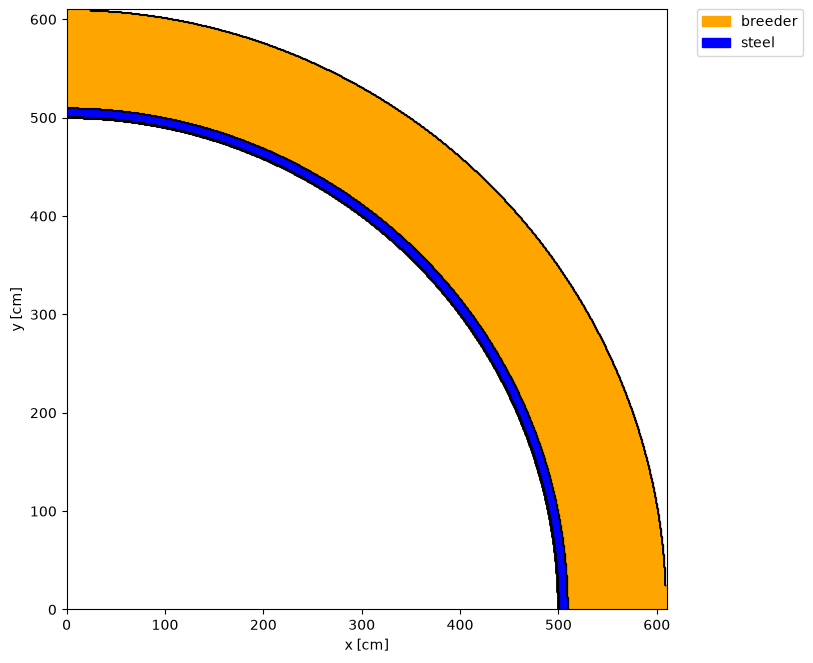

In [13]:
openmc_model = openmc.Model(**model)
colors = {
    mats_dic['breeder']: 'orange',
    mats_dic['steel']: 'blue',
}

R = 610

ax = openmc_model.plot(
    basis='xy',
    origin=(R/2, R/2, 0),
    width=(R, R),
    color_by='material',
    colors=colors,
    outline=True,
    legend=True,
    pixels=(600, 600),
)

## 7. Run

In [14]:
sp_filename = openmc_model.run(cwd=output_dir)

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

## 8. Output

In [15]:
with openmc.StatePoint(sp_filename) as sp:
    tally_n_Xt = sp.get_tally(name='(n,Xt)')
    tally_convergence = sp.get_tally(name='(n,Xt)_convergence')
    tally_map = sp.get_tally(name='fluence_n_Xt_r_E')
    tally_r = sp.get_tally(name='fluence_n_Xt_r')

### (n,Xt)_convergence

In [16]:
rel_err = tally_convergence.get_values(value='rel_err').item()

tally = next(t for t in openmc_model.tallies
             if t.name == '(n,Xt)_convergence')
trigger_value = tally.triggers[0].threshold

rel_err, trigger_value

(0.002414314938429203, 0.003)

In [17]:
if rel_err > trigger_value:
    assert sp.current_batch >= openmc_model.settings.trigger_max_batches

### (n,Xt)

In [18]:
tally_n_Xt

Tally
	ID             =	1
	Name           =	(n,Xt)
	Filters        =	CellFilter
	Nuclides       =	Pb204 Pb206 Pb207 Pb208 Li6 Li7 total
	Scores         =	['(n,Xt)']
	Estimator      =	tracklength
	Multiply dens. =	True

In [19]:
df_n_Xt = tally_n_Xt.get_pandas_dataframe()
df_n_Xt['rel_err'] = df_n_Xt['std. dev.'] / df_n_Xt['mean'].abs()
df_n_Xt.sort_values('mean', ascending=False)

,cell,nuclide,score,mean,std. dev.,rel_err
6,3,total,"(n,Xt)",1.021593e+00,2.466447e-03,0.002414
4,3,Li6,"(n,Xt)",1.017997e+00,2.447643e-03,0.002404
5,3,Li7,"(n,Xt)",3.595710e-03,2.645250e-05,0.007357
3,3,Pb208,"(n,Xt)",7.207443e-08,5.291830e-10,0.007342
2,3,Pb207,"(n,Xt)",2.362241e-08,1.718703e-10,0.007276
0,3,Pb204,"(n,Xt)",1.763990e-08,1.278332e-10,0.007247
1,3,Pb206,"(n,Xt)",0.000000e+00,0.000000e+00,NaN


### Neutron fluence: radius–energy maps

The fluence map is normalized by spherical-shell volume and lethargy-bin width.
The second map shows relative statistical error; bins with zero fluence are blank.

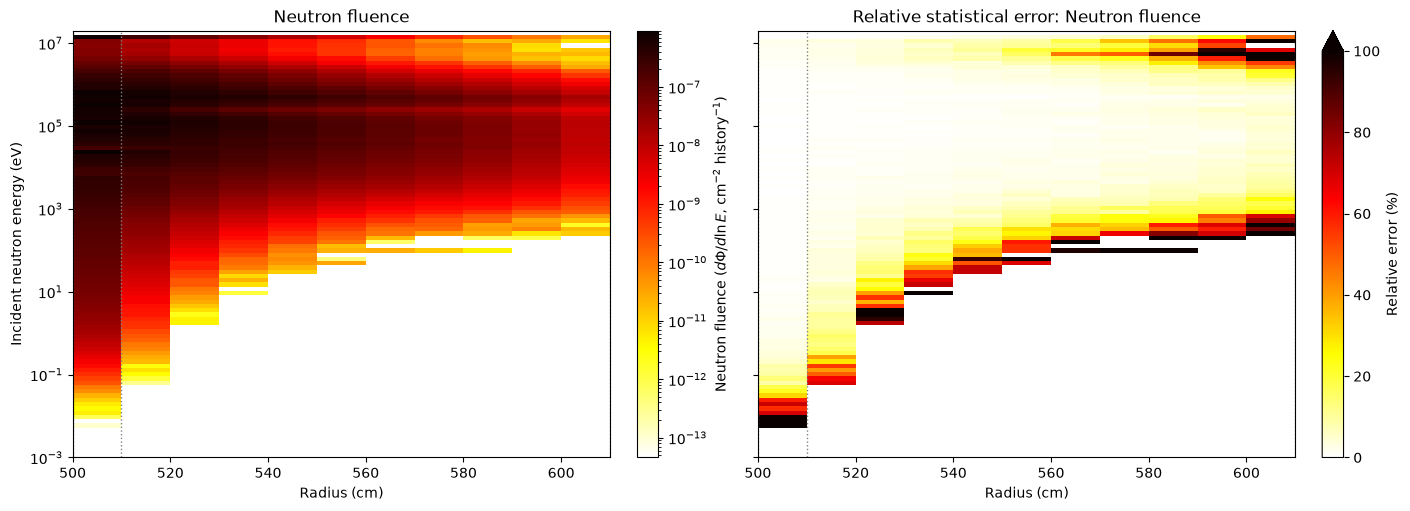

In [20]:
def plot_map_pair(values, rel_err, title, cbar_label):
    """Plot a volume-normalized radius–energy map and its relative error."""
    values_plot = np.ma.masked_less_equal(values.T, 0)
    err_plot = np.ma.masked_invalid(100 * rel_err.T)

    fig, axes = plt.subplots(
        1, 2, figsize=(14, 5), sharex=True, sharey=True,
        layout='constrained',
    )

    pcm_value = axes[0].pcolormesh(
        mesh.r_grid, energy_filter.values, values_plot,
        cmap='hot_r', norm=LogNorm(), shading='auto',
    )
    pcm_err = axes[1].pcolormesh(
        mesh.r_grid, energy_filter.values, err_plot,
        cmap='hot_r', vmin=0, vmax=100, shading='auto',
    )

    for ax in axes:
        ax.set(yscale='log', xlabel='Radius (cm)')
        for r in geom_df['radius_cm']:
            ax.axvline(r, color='gray', ls=':', lw=1)

    axes[0].set(title=title, ylabel='Incident neutron energy (eV)')
    axes[1].set_title(f'Relative statistical error: {title}')

    fig.colorbar(pcm_value, ax=axes[0], label=cbar_label)
    fig.colorbar(pcm_err, ax=axes[1], label='Relative error (%)', extend='max')
    plt.show()


# Extract the neutron fluence score from the radius–energy tally.
fluence_tally = tally_map.get_slice(scores=['flux'])
mesh = tally_map.find_filter(openmc.MeshFilter).mesh
energy_filter = tally_map.find_filter(openmc.EnergyFilter)

fluence = fluence_tally.get_reshaped_data(value='mean').squeeze()
fluence_std = fluence_tally.get_reshaped_data(value='std_dev').squeeze()

volumes = mesh.volumes[:, 0, 0]
du = np.log(E_edges[1:] / E_edges[:-1])
fluence_per_lethargy = fluence / volumes[:, None] / du[None, :]

# Relative error is undefined where the mean is zero.
fluence_rel_err = np.full_like(fluence, np.nan)
np.divide(fluence_std, np.abs(fluence), out=fluence_rel_err, where=fluence != 0)

plot_map_pair(
    fluence_per_lethargy,
    fluence_rel_err,
    'Neutron fluence',
    r'Neutron fluence ($d\Phi/d\ln E$, cm$^{-2}$ history$^{-1}$)',
)

### (n,Xt) production: radius–energy maps

The `(n,Xt)` score is binned by **incident neutron energy**. Values are divided by shell volume and lethargy-bin width. The error map shows the relative statistical error; bins with zero production are blank.

The maps and profile cover the radial mesh, including the first wall. The original cell-filtered `(n,Xt)` tally above remains the TBR tally.

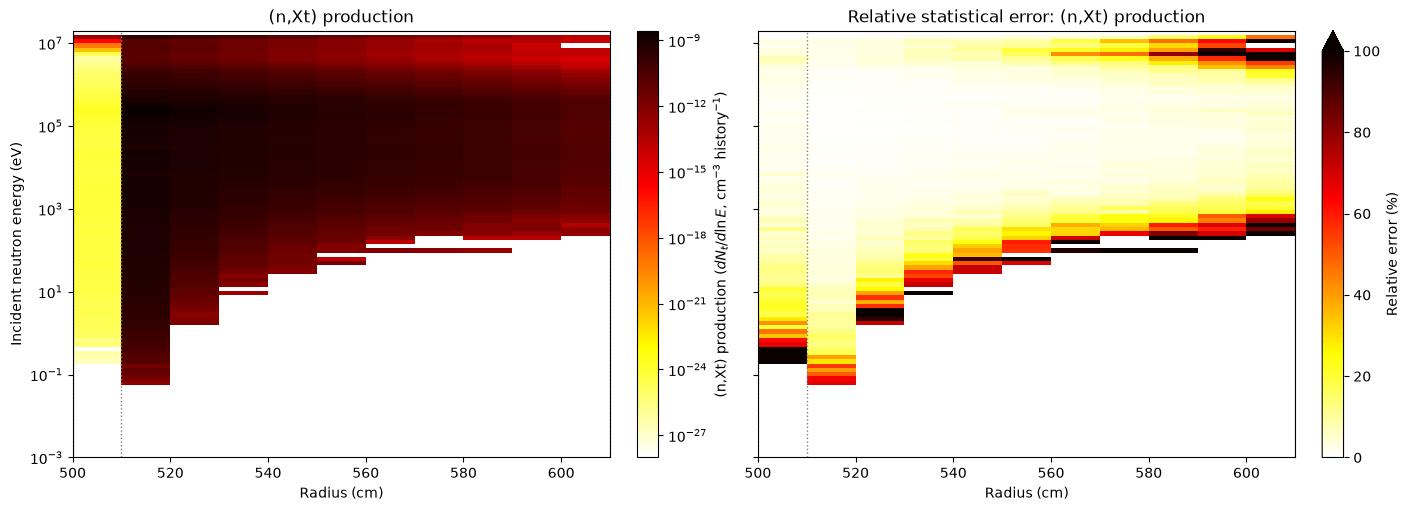

In [21]:
n_Xt_tally = tally_map.get_slice(scores=['(n,Xt)'])

n_Xt = n_Xt_tally.get_reshaped_data(value='mean').squeeze()
n_Xt_std = n_Xt_tally.get_reshaped_data(value='std_dev').squeeze()
n_Xt_per_lethargy = n_Xt / volumes[:, None] / du[None, :]

n_Xt_rel_err = np.full_like(n_Xt, np.nan)
np.divide(n_Xt_std, np.abs(n_Xt), out=n_Xt_rel_err, where=n_Xt != 0)

plot_map_pair(
    n_Xt_per_lethargy,
    n_Xt_rel_err,
    '(n,Xt) production',
    r'(n,Xt) production ($dN_t/d\ln E$, cm$^{-3}$ history$^{-1}$)',
)

### Energy-integrated radial contributions per spherical shell

The two profiles show neutron track-length and (n,Xt) production integrated over each spherical shell (without dividing by shell volume). (n,Xt) data points represent each shell's incremental contribution to TBR.

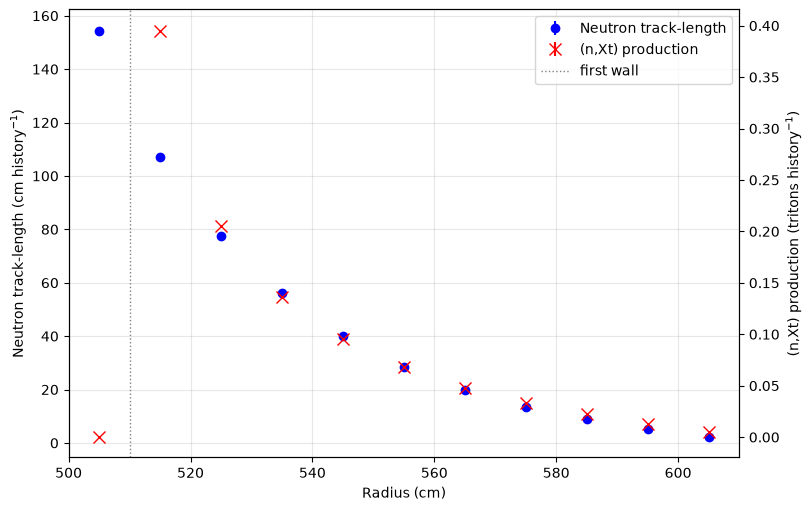

In [22]:
mesh_r = tally_r.find_filter(openmc.MeshFilter).mesh
fluence_r_tally = tally_r.get_slice(scores=['flux'])
n_Xt_r_tally = tally_r.get_slice(scores=['(n,Xt)'])

# Tally results are integrated over each spherical shell and over energy.
# Do not divide by shell volume: plot total track-length and (n,Xt) production.
fluence_r = fluence_r_tally.get_reshaped_data(value='mean').squeeze()
fluence_r_std = fluence_r_tally.get_reshaped_data(value='std_dev').squeeze()
n_Xt_r = n_Xt_r_tally.get_reshaped_data(value='mean').squeeze()
n_Xt_r_std = n_Xt_r_tally.get_reshaped_data(value='std_dev').squeeze()

r_mid = (mesh_r.r_grid[:-1] + mesh_r.r_grid[1:]) / 2

fig, ax_fluence = plt.subplots(figsize=(8, 5), layout='constrained')
ax_n_Xt = ax_fluence.twinx()

fluence_profile = ax_fluence.errorbar(
    r_mid, fluence_r, yerr=fluence_r_std,
    fmt='o', ls='none',
    color='blue', ecolor='blue',
    label='Neutron track-length',
)
n_Xt_profile = ax_n_Xt.errorbar(
    r_mid, n_Xt_r, yerr=n_Xt_r_std,
    fmt='x', ls='none', ms=8,
    color='red', ecolor='red',
    label='(n,Xt) production',
)

r = geom_df.loc['first_wall', 'radius_cm']
first_wall = ax_fluence.axvline(r, color='gray', ls=':', lw=1, label='first wall')

ax_fluence.set(
    xlabel='Radius (cm)',
    ylabel='Neutron track-length (cm history$^{-1}$)',
    xlim=(mesh_r.r_grid[0], mesh_r.r_grid[-1]),
)
ax_n_Xt.set_ylabel('(n,Xt) production (tritons history$^{-1}$)')

ax_fluence.grid(alpha=0.3)
ax_fluence.legend(
    [fluence_profile, n_Xt_profile, first_wall],
    [fluence_profile.get_label(), n_Xt_profile.get_label(), first_wall.get_label()],
)